# Packed-bed reactor: fitting the design equation

As sucrose flows through the packed bed, the immobilized invertase hydrolyzes it, so the conversion leaving the column depends on how long the fluid spends in the reactor. Fitting the packed-bed design equation to your conversions gives $V_{max}$, the maximum reaction rate of the catalyst in the column.

This notebook works through five parts:

1. **Fit $V_{max}$** by comparing the design equation with your measured conversions.
2. **Report a 95% confidence interval** for $V_{max}$.
3. **Check the interval** by plotting how the fit worsens as $V_{max}$ moves away from its best value.
4. **Check the residuals** for patterns the model does not capture.
5. **Summarize** the results in a table.

**To use it:** put your data file in the same folder as this notebook and check the settings cell. Then choose **Run → Run All Cells** from the menu. The cells depend on one another, so they must run in order from the top; running only a later cell gives a `NameError`. After changing a setting, run all cells again.

## Settings

The data file needs one row per run, with the flow rate in mL/min and the measured steady-state conversion. Any other columns are ignored. The residence time is calculated from the flow rate and the total column volume set below.

In [4]:
DATA_FILE = "reactor_data.csv"

# Column headers in the data file.
FLOW = "FlowRate_mL_per_min"
CONV = "Conversion"

# Total volume of the packed column (mL).
COLUMN_VOLUME = 100.0

# Feed sucrose concentration (mg/mL).
C_A0 = 25.0

# Michaelis constant for invertase acting on sucrose, held fixed (mg/mL). Literature value.
K_M = 3.91

# Starting guess for the fit (mg/mL/min).
V_MAX_GUESS = 1.0

In [5]:
import os
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit
from scipy.special import lambertw
from scipy.stats import t as t_dist

warnings.filterwarnings("ignore", message=".*parameter as float was deprecated.*")

if not os.path.exists(DATA_FILE):
    csv_files = sorted(f for f in os.listdir(".") if f.lower().endswith(".csv"))
    raise FileNotFoundError(
        f'Cannot find "{DATA_FILE}" in the folder this notebook is in.\n'
        f"CSV files in this folder: {', '.join(csv_files) if csv_files else 'none'}.\n"
        "Move your data file into this folder, or change DATA_FILE in the settings cell to match its name exactly.")
df = pd.read_csv(DATA_FILE)
df.columns = [col.strip() for col in df.columns]
df = df.dropna(subset=[c for c in (FLOW, CONV) if c in df.columns])
missing_cols = [c for c in (FLOW, CONV) if c not in df.columns]
if missing_cols:
    raise KeyError(f"Column(s) {missing_cols} not found. The file's columns are: {list(df.columns)}.")

Q = df[FLOW].to_numpy(float)             # mL/min
X_exp = df[CONV].to_numpy(float)         # dimensionless
tau_exp = COLUMN_VOLUME / Q              # residence time, min

for q, tau, x in zip(Q, tau_exp, X_exp):
    print(f"Flow {q:g} mL/min: residence time {tau:.2f} min, conversion {x:.3f}")

Flow 71 mL/min: residence time 1.41 min, conversion 0.074
Flow 37.8 mL/min: residence time 2.65 min, conversion 0.131
Flow 8.675 mL/min: residence time 11.53 min, conversion 0.449
Flow 4.5 mL/min: residence time 22.22 min, conversion 0.510
Flow 18 mL/min: residence time 5.56 min, conversion 0.535
Flow 48 mL/min: residence time 2.08 min, conversion 0.288
Flow 30 mL/min: residence time 3.33 min, conversion 0.056
Flow 10 mL/min: residence time 10.00 min, conversion 0.143
Flow 20 mL/min: residence time 5.00 min, conversion 0.110
Flow 70.955 mL/min: residence time 1.41 min, conversion 0.184
Flow 4.619 mL/min: residence time 21.65 min, conversion 0.702
Flow 37.787 mL/min: residence time 2.65 min, conversion 0.260
Flow 37.787 mL/min: residence time 2.65 min, conversion 0.269
Flow 54.371 mL/min: residence time 1.84 min, conversion 0.192
Flow 21.203 mL/min: residence time 4.72 min, conversion 0.384
Flow 79.247 mL/min: residence time 1.26 min, conversion 0.122
Flow 54.371 mL/min: residence time 

## Part 1. Fitting $V_{max}$

**The model.** If the bed behaves as a plug-flow reactor and the reaction follows Michaelis-Menten kinetics, a sucrose balance integrated along the column gives the packed-bed design equation. This is the equation you are fitting:

$$\tau = \frac{V_{Reactor}}{Q} = \frac{C_{A0}}{(1-\varepsilon)\,\rho_{enzyme}\,\Omega\,k_{cat}}\left[X + \frac{K_M}{C_{A0}} \ln\left(\frac{1}{1-X}\right)\right]$$

The denominator of the term in front of the brackets is the maximum reaction rate per volume of packed column:

$$V_{max} = (1-\varepsilon)\,\rho_{enzyme}\,\Omega\,k_{cat}$$

- $\varepsilon$ is the void fraction of the bed, so $1-\varepsilon$ is the fraction of the column volume occupied by beads.
- $\rho_{enzyme}$ is the invertase loading in the beads.
- $\Omega$ is the effectiveness factor: the observed rate in the beads divided by the rate the same enzyme would give with no diffusion limitation.
- $k_{cat}$ is the turnover number of invertase, the rate at which each unit of enzyme converts sucrose when it is saturated.

These four quantities are not fitted separately. Together they make up $V_{max}$, the one parameter fitted to your data, in mg sucrose per mL of column per minute. Everything inside the brackets depends only on the conversion and the fixed $K_M$ and $C_{A0}$, so $V_{max}$ sets how long the column needs to reach a given conversion: doubling $V_{max}$ halves the residence time needed.

Here $X$ is the conversion, $C_{A0}$ the feed sucrose concentration, $Q$ the flow rate, and $\tau = V_{Reactor}/Q$ the residence time, with $V_{Reactor}$ the total column volume. This $\tau$ is not the mean residence time $t_m$ from the RTD analysis, which uses only the liquid between the beads. $K_M$ is held fixed at the value set above.

**The fit.** Conversion is what you measured, while the residence time was set by the pump, so the fit predicts conversion from residence time. The design equation gives $\tau$ for a known $X$ and cannot be rearranged for $X$ with ordinary algebra. It can, however, be written using the Lambert W function, which SciPy provides as `lambertw`:

$$X = 1 - \frac{K_M}{C_{A0}}\,W\!\left[\frac{C_{A0}}{K_M}\exp\!\left(\frac{C_{A0} - V_{max}\,\tau}{K_M}\right)\right]$$

W undoes the function $w\,e^w$ in the same way that ln undoes $e^x$; you do not need to work with it directly. $V_{max}$ appears inside this expression, so it is found by nonlinear least squares: the notebook adjusts $V_{max}$ and finds the value that makes the sum of squared residuals (SSR) between the predicted and measured conversions as small as possible. The plot shows your data with the best-fit model.

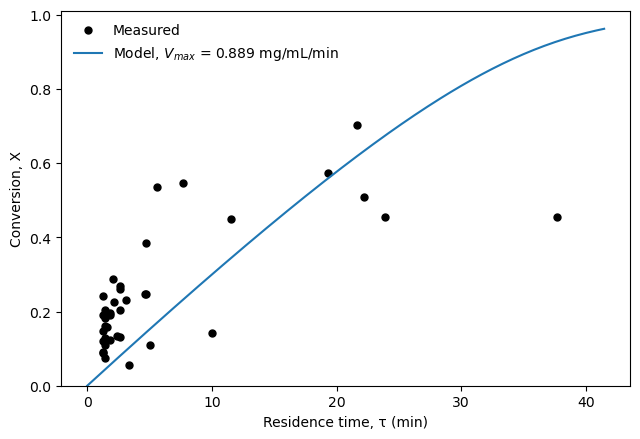

In [7]:
def X_model(tau, V_max):
    arg = (C_A0 / K_M) * np.exp((C_A0 - V_max * tau) / K_M)
    return 1 - (K_M / C_A0) * lambertw(arg).real


popt, pcov = curve_fit(X_model, tau_exp, X_exp, p0=[V_MAX_GUESS], bounds=(1e-6, np.inf))
V_max = popt[0]
X_fit = X_model(tau_exp, V_max)

n = len(X_exp)
ssr = np.sum((X_exp - X_fit)**2)
s2 = ssr / (n - 1)                     # average squared residual (MSE), n - 1 degrees of freedom
se = np.sqrt(pcov[0, 0])               # standard error of V_max
t_crit = t_dist.ppf(0.975, n - 1)
half = t_crit * se                     # half-width of the 95% CI

tau_fine = np.linspace(0, 1.1 * tau_exp.max(), 200)
fig, ax = plt.subplots(figsize=(6.5, 4.5))
ax.plot(tau_exp, X_exp, "o", color="black", ms=5, label="Measured")
ax.plot(tau_fine, X_model(tau_fine, V_max), "-", color="tab:blue",
        label=f"Model, $V_{{max}}$ = {V_max:.3g} mg/mL/min")
ax.set_xlabel("Residence time, τ (min)")
ax.set_ylabel("Conversion, X")
ax.set_ylim(bottom=0)
ax.legend(frameon=False)
fig.tight_layout()
plt.show()

## Part 2. Confidence interval for $V_{max}$

Your best-fit $V_{max}$ comes from one set of noisy measurements, so it is reported with a 95% confidence interval: estimate $\pm\ t \times se$, where $se$ is the standard error and $t$ comes from the t-distribution.

**Where the standard error comes from.** You have seen the standard error of a straight line's slope:

$$se(\hat\beta_1) = \sqrt{\frac{s^2}{\sum (x_i - \bar x)^2}}, \qquad s^2 = \frac{\sum (y_i - \hat y_i)^2}{n - 2}$$

The numerator, $s^2$, is the average squared residual: how much the data scatter around the fit. The denominator is how strongly the fit responds to the slope: if the slope changes by $\Delta\beta_1$, each fitted value moves by $(x_i - \bar x)\,\Delta\beta_1$. So the standard error is the scatter of the data divided by how strongly the fitted values respond to the parameter.

The design equation uses the same idea for $V_{max}$:

$$se(\hat V_{max}) = \sqrt{\frac{s^2}{\sum \left(\Delta \hat X_i / \Delta V_{max}\right)^2}}, \qquad s^2 = \frac{\sum (X_i - \hat X_i)^2}{n - 1}$$

Here $X_i$ is the measured conversion in run $i$, $\hat X_i$ the predicted one, and $n$ the number of runs. The denominator of $s^2$ is $n - 1$ because one parameter, $V_{max}$, is fitted. Rather than differentiate the Lambert W expression, the notebook changes $V_{max}$ slightly, recalculates the predicted conversions, and measures how far each one moves. Runs at long residence times usually move the most, so they do most of the work of pinning $V_{max}$ down.

In [9]:
print(f"{n} runs, t = {t_crit:.3f}")
print(f"V_max = {V_max:.3g} ± {half:.2g} mg/mL/min   (95% CI {V_max - half:.3g} to {V_max + half:.3g})")

39 runs, t = 2.024
V_max = 0.889 ± 0.22 mg/mL/min   (95% CI 0.665 to 1.11)


## Part 3. Sensitivity of the fit to $V_{max}$

The plot below changes $V_{max}$ around its best-fit value and shows how much worse the fit gets, measured by the sum of squared residuals (SSR). The SSR is lowest at the best-fit value and rises on either side.

The confidence interval in Part 2 is an approximation. It uses how sharply the SSR curves upward at the best-fit value and assumes the curve keeps that same curvature everywhere, like a parabola. This plot checks that approximation.

- The **solid curve** is the SSR calculated by recalculating the model with your data at each value. This is the real SSR curve.
- The **dotted parabola** is the SSR curve the confidence interval assumes.
- The **shaded band** is the 95% confidence interval from Part 2.
- The **dashed line** marks the height of the parabola at the edges of the interval: how much worse the fit is allowed to get before you leave the interval.

**Interpreting your results.** Look first at how sharply the SSR curve rises on either side of its minimum. This curvature is the denominator of the standard error in Part 2: how strongly the predicted conversions respond when $V_{max}$ changes. If they respond strongly, even a small change in $V_{max}$ makes the fit noticeably worse, so the curve rises sharply and the interval is narrow. If they barely respond, the curve is broad and flat near its minimum, and a wider range of values fits nearly as well. Noisier data (a larger MSE, the numerator) raise the dashed line and widen the interval.

Then check the approximation. Follow the dashed line and see where the solid curve crosses it. If it crosses at the edges of the shaded band, the real SSR curve matches the parabola and the interval is reliable. If it crosses outside the band on one side, the real curve rises more slowly there, and the interval should extend further on that side.

Finally, the interval assumes the residuals are random scatter, which Part 4 checks. A narrow interval means your data pin $V_{max}$ down for this model, not that the model is right. If the residuals show a pattern, the true uncertainty is larger than the interval.

**Questions to consider**

1. How tightly do your data pin $V_{max}$ down? Express the interval's half-width as a percentage of the best-fit value.
2. Does the solid curve follow the dotted parabola on both sides? If not, on which side should the interval extend further?

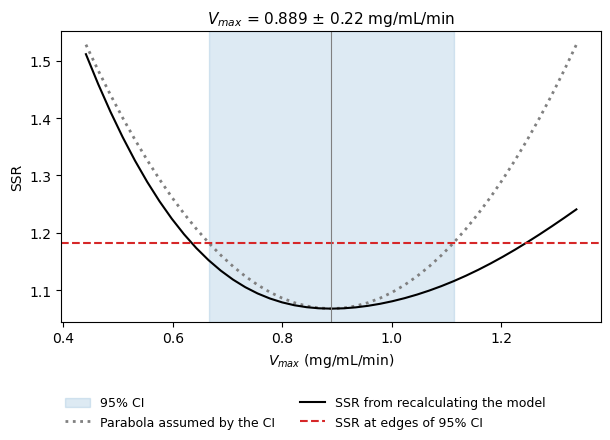

In [11]:
threshold = ssr + t_crit**2 * s2       # height of the parabola at the edges of the 95% CI
v_line = np.linspace(max(V_max - 2 * half, 0.2 * V_max), V_max + 2 * half, 41)
ssr_line = [np.sum((X_model(tau_exp, v) - X_exp)**2) for v in v_line]
parabola = ssr + s2 * ((v_line - V_max) / se)**2

fig, ax = plt.subplots(figsize=(6.5, 4.4))
ax.axvspan(V_max - half, V_max + half, color="tab:blue", alpha=0.15, label="95% CI")
ax.plot(v_line, parabola, ":", color="gray", linewidth=2, label="Parabola assumed by the CI")
ax.plot(v_line, ssr_line, "-", color="black", label="SSR from recalculating the model")
ax.axhline(threshold, color="tab:red", linestyle="--", label="SSR at edges of 95% CI")
ax.axvline(V_max, color="gray", linewidth=0.8)
ax.set_title(f"$V_{{max}}$ = {V_max:.3g} ± {half:.2g} mg/mL/min", fontsize=11)
ax.set_xlabel("$V_{max}$ (mg/mL/min)")
ax.set_ylabel("SSR")
fig.legend(loc="lower center", ncol=2, frameon=False, fontsize=9)
fig.subplots_adjust(left=0.14, right=0.97, bottom=0.26, top=0.92)
plt.show()

## Part 4. Residuals

A residual is the measured conversion minus the predicted one. If the model describes your column, the residuals scatter randomly above and below zero across the whole range of conversions. A run of residuals on one side of zero, or a steady trend, means the model is missing something about how sucrose was converted in the column. The residuals are plotted against the predicted conversion.

**Questions to consider**

1. Are the residuals scattered randomly about zero, or do they lean to one side over part of the range? Where does the model miss most?
2. If the residuals show a pattern, what might the design equation leave out about how fluid moves through the bed or how sucrose reaches the enzyme?
3. Does any single run stand out from the rest?

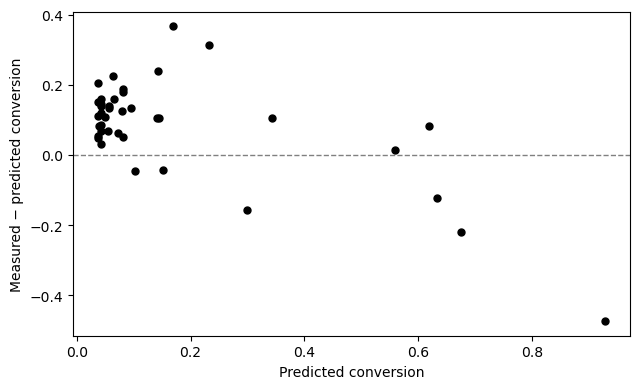

In [13]:
fig, ax = plt.subplots(figsize=(6.5, 4))
ax.axhline(0, color="gray", linestyle="--", linewidth=1)
ax.plot(X_fit, X_exp - X_fit, "o", color="black", ms=5)
ax.set_xlabel("Predicted conversion")
ax.set_ylabel("Measured − predicted conversion")
fig.tight_layout()
plt.show()

## Part 5. Summary

The table collects the measured and predicted conversion for each run and is saved as `pbr_results.csv` for formatting in your report. Report $V_{max}$ with its 95% confidence interval from Part 2.

In [15]:
summary = pd.DataFrame({
    "Flow (mL/min)": Q, "Residence time τ (min)": np.round(tau_exp, 2),
    "Measured X": np.round(X_exp, 3), "Predicted X": np.round(X_fit, 3),
    "Residual": np.round(X_exp - X_fit, 3)})
print(summary.to_string(index=False))
print(f"\nV_max = {V_max:.3g} ± {half:.2g} mg/mL/min (95% CI), with K_M = {K_M:g} mg/mL fixed")
summary.to_csv("pbr_results.csv", index=False)

 Flow (mL/min)  Residence time τ (min)  Measured X  Predicted X  Residual
     71.000000                    1.41       0.074        0.043     0.031
     37.800000                    2.65       0.131        0.081     0.051
      8.675000                   11.53       0.449        0.344     0.105
      4.500000                   22.22       0.510        0.633    -0.123
     18.000000                    5.56       0.535        0.169     0.366
     48.000000                    2.08       0.288        0.064     0.224
     30.000000                    3.33       0.056        0.102    -0.046
     10.000000                   10.00       0.143        0.300    -0.157
     20.000000                    5.00       0.110        0.152    -0.042
     70.955000                    1.41       0.184        0.043     0.140
      4.619000                   21.65       0.702        0.619     0.083
     37.787000                    2.65       0.260        0.081     0.179
     37.787000                    2.65